In [5]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

In [16]:
datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

In [ ]:
train = datagen.flow_from_directory(
    "PetImages",
    target_size=(150, 150),
    batch_size=32,
    class_mode="binary",
    subset="training"
)

Found 20000 images belonging to 2 classes.


In [ ]:
val = datagen.flow_from_directory(
    "PetImages",
    target_size=(150, 150),
    batch_size=32,
    class_mode="binary",
    subset="validation"
)


Found 4998 images belonging to 2 classes.


In [19]:
model = models.Sequential([
    tf.keras.Input(shape=(150,150,3)),

    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer="adam",
              loss="binary_crossentropy",
              metrics=["accuracy"])


In [20]:
history = model.fit(train, epochs=10, validation_data=val)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 140s 221ms/step - accuracy: 0.6791 - loss: 0.5924 - val_accuracy: 0.6921 - val_loss: 0.5599
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 140s 223ms/step - accuracy: 0.7831 - loss: 0.4601 - val_accuracy: 0.7517 - val_loss: 0.5062
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 140s 224ms/step - accuracy: 0.8275 - loss: 0.3862 - val_accuracy: 0.8195 - val_loss: 0.4240
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 140s 224ms/step - accuracy: 0.8590 - loss: 0.3247 - val_accuracy: 0.8035 - val_loss: 0.4586
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 141s 225ms/step - accuracy: 0.9002 - loss: 0.2367 - val_accuracy: 0.8255 - val_loss: 0.4231
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 141s 226ms/step - accuracy: 0.9428 - loss: 0.1431 - val_accuracy: 0.8311 - val_loss: 0.5199
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 141s 226ms/step - accuracy: 0.9729 - loss: 0.0743 - val_accuracy: 0.8143 - val_loss: 0.7270
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 141s 225ms/step - accuracy: 0.9839 -

In [21]:
model.save("cat_dog_classifier.h5")
print("Model saved successfully!")

Model saved successfully!


In [2]:
#model = tf.keras.models.load_model("cat_dog_classifier.h5")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


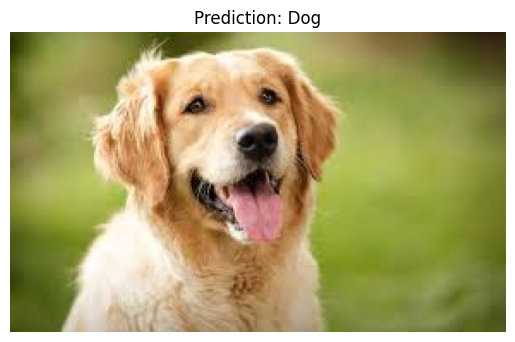

In [ ]:
def predict_and_show(img_path):
    img = load_img(img_path, target_size=(150, 150))

    plt.imshow(load_img(img_path))
    plt.axis("off")

    img_array = img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    pred = model.predict(img_array)[0][0]

    if pred > 0.5:
        label = "Dog"
    else:
        label = "Cat"

    plt.title(f"Prediction: {label}")
    plt.show()

predict_and_show("test dog.jpeg")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


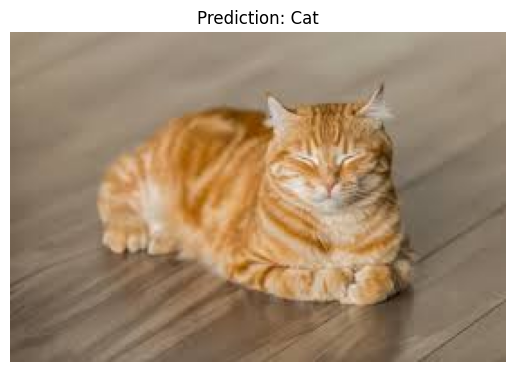

In [ ]:
def predict_and_show(img_path):
    img = load_img(img_path, target_size=(150, 150))

    plt.imshow(load_img(img_path))
    plt.axis("off")

    img_array = img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    pred = model.predict(img_array)[0][0]

    if pred > 0.5:
        label = "Dog"
    else:
        label = "Cat"

    plt.title(f"Prediction: {label}")
    plt.show()

predict_and_show("test cat.jpeg")